# Análisis de errores y correlaciones (validación)

Complementa las tablas agregadas (mAP, P/R/F1, AP por clase y tamaño) con lo que
esas cifras no dicen: **qué errores comete cada modelo, dónde y por qué**.
Pensado para responder en la defensa a "¿qué tipo de errores comete?", "¿hay
correlaciones?" y "¿cómo se llevaría esto a un caso práctico?".

## Qué contiene

1. **FP y FN por modelo** en su punto de operación (el umbral de máximo F1).
2. **Taxonomía de errores** (simplificación del esquema TIDE): cada FP es
   *duplicado*, *confusión de clase*, *mal localizado* o *fondo*; cada FN es
   *confusión de clase*, *asignado a otro GT*, *mal localizado* o *no detectado*.
3. **FN por tamaño, por clase y por condición** (hora del día, clima).
4. **Matrices de confusión** (9 clases + fondo) por modelo.
5. **Correlaciones**: instancias↔AP por clase (con control por tamaño), tamaño↔detección,
   confianza↔acierto, densidad de escena↔recall, solapamiento de errores entre
   modelos, y precisión↔velocidad↔coste a nivel de modelo (18 runs).
6. **Curvas de punto de operación** (P, R, FP/img, FN/img frente al umbral).

## Convenciones (idénticas al protocolo de la memoria)

- Emparejamiento TP/FP/FN: greedy por score descendente, **misma clase**, **IoU ≥ 0,5**
  (el criterio de `DetectionEvaluator._match()` en `evaluate.py`).
- Coordenadas **nativas 1280×720**; tamaños small/medium/large con los cortes de COCO
  (32² y 96² px).
- Las predicciones se guardan a `conf=0,001` y `max_det=100` (protocolo común) y
  después se filtran al umbral que se analice.
- La clase `train` se **excluye** (2 instancias en val, AP no interpretable), igual
  que en las tablas de la memoria. Se cambia en `EXCLUIR`.

## Límites que conviene tener presentes

- **Una sola semilla** (`SEMILLA = 0`) para el análisis de errores. Las cifras agregadas
  de la memoria son media de tres semillas; aquí las de P/R pueden diferir unas décimas
  o algún punto. La celda de validación lo cuantifica.
- Cada modelo se analiza **en su propio umbral de máximo F1**, así que las comparaciones
  de FP/FN entre modelos mezclan modelo y punto de operación. Para comparar a igualdad de
  condiciones, usar la sección 6.
- La taxonomía es una **simplificación** de TIDE (no separa «clase+localización» ni
  distingue FP «de fondo» entre real y de anotación incompleta).
- Las correlaciones por clase tienen **n = 9** (clases) y las de modelo **n = 6** o 18:
  son **exploratorias**; correlación no implica causa.

In [1]:
import json
import pickle
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from scipy import stats
from sklearn.metrics import roc_auc_score
from torch.amp import autocast
from torch.utils.data import DataLoader
from torchvision.ops import box_iou
from tqdm.auto import tqdm

sys.path.insert(0, "..")  # evaluate.py y data/ viven en la raiz de TFM/
import evaluate
from data.dataset import BDD100KDetection

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path("..")
RUNS = ROOT / "runs"
FIG_DIR = Path("figuras_errores"); FIG_DIR.mkdir(exist_ok=True)
TAB_DIR = Path("tablas_errores");  TAB_DIR.mkdir(exist_ok=True)
CACHE_DIR = Path("cache_predicciones"); CACHE_DIR.mkdir(exist_ok=True)
DEVICE = torch.device(evaluate.DEVICE_TYPE)

# ---- parametros del analisis ------------------------------------------------
SEMILLA = 0                       # semilla de los runs que se analizan (0, 1 o 2)
IOU_MATCH = 0.5                   # mismo umbral que mAP@50 y que P/R/F1
IOU_LOC_MIN = 0.1                 # IoU minimo para llamar "mal localizado" a un error
CONF_CACHE = evaluate.DEFAULT_CONF   # 0.001: las predicciones se guardan asi
EXCLUIR = {"train"}               # clases fuera del analisis (2 instancias en val)
RECALCULAR_INFERENCIA = False     # True para ignorar la cache de predicciones
AREA_SMALL, AREA_LARGE = 32 ** 2, 96 ** 2

CLASS_NAMES = evaluate.CLASS_NAMES
KEEP = [i for i, n in enumerate(CLASS_NAMES) if n not in EXCLUIR]
NAMES_K = [CLASS_NAMES[i] for i in KEEP]
NK = len(KEEP)
LUT = np.full(len(CLASS_NAMES), -1, dtype=np.int64)
LUT[KEEP] = np.arange(NK)         # id original -> posicion en el analisis
SHORT = {"traffic light": "t.light", "traffic sign": "t.sign"}
NAMES_S = [SHORT.get(n, n) for n in NAMES_K]
# Clases con equivalente directo en MS COCO (memoria, sec. Preentrenamiento):
# 7 de 9; rider y traffic sign solo tienen correspondencia parcial o ninguna.
EN_COCO = {"person": 1, "rider": 0, "car": 1, "truck": 1, "bus": 1, "motor": 1,
           "bike": 1, "traffic light": 1, "traffic sign": 0}

# ---- estilo (misma paleta que graficas_resultados) --------------------------
COLORES = {"YOLO11m (A)": "#2a78d6", "YOLO11m (B)": "#eb6834", "Faster R-CNN": "#1baf7a",
           "SSD300": "#eda100", "DETR": "#e87ba4", "CNN baseline": "#008300"}
INK_PRIMARY, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"
GRID_COLOR, BASELINE_COLOR, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#1c5cab", "#0d366b"]
CMAP = LinearSegmentedColormap.from_list("seq_blue", ["#ffffff"] + SEQ_BLUE)
COL_TIPOS = ["#2a78d6", "#eb6834", "#1baf7a", "#898781"]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE_COLOR, "axes.labelcolor": INK_SECONDARY,
    "xtick.color": INK_SECONDARY, "ytick.color": INK_SECONDARY, "text.color": INK_PRIMARY,
    "axes.grid": True, "grid.color": GRID_COLOR, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "axes.titlesize": 10, "legend.frameon": False,
})


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{nombre}.png", dpi=200, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{nombre}.pdf", bbox_inches="tight")
    plt.show()


def heatmap(ax, M, xl, yl, fmt="{:.0f}", vmax=None, fs=7, annot=True):
    M = np.asarray(M, dtype=float)
    vmax = vmax if vmax is not None else (np.nanmax(M) if np.isfinite(M).any() else 1.0)
    ax.imshow(M, cmap=CMAP, vmin=0, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(xl))); ax.set_xticklabels(xl, rotation=45, ha="right")
    ax.set_yticks(range(len(yl))); ax.set_yticklabels(yl)
    ax.grid(False)
    if annot:
        for (i, j), v in np.ndenumerate(M):
            if np.isfinite(v) and v > 0:
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fs,
                        color="white" if v > 0.6 * vmax else INK_PRIMARY)


def wilson(k, n, z=1.96):
    # intervalo de Wilson para una proporcion k/n
    if n == 0:
        return np.nan, np.nan
    p = k / n
    den = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / den
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return c - h, c + h


print("Dispositivo:", DEVICE, "| clases analizadas:", NAMES_K)

c:\Users\julio\anaconda3\envs\tfm\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dispositivo: cuda | clases analizadas: ['person', 'rider', 'car', 'truck', 'bus', 'motor', 'bike', 'traffic light', 'traffic sign']


## 1. Datos: ground truth, atributos de escena y predicciones

El GT se lee una sola vez, en coordenadas nativas, y es **idéntico para los seis
modelos**. Los atributos de escena (hora del día, clima) salen del JSON original de
BDD100K y permiten medir el recall por condición.

Las predicciones se calculan **una vez por modelo a `conf=0,001`** y se guardan en
`cache_predicciones/`; todo el análisis posterior se hace sobre esa cache, así que se
puede cambiar de umbral sin volver a inferir. Los modelos se cargan de uno en uno y se
libera la GPU entre ellos (8 GB de VRAM).

In [2]:
bdd = yaml.safe_load((ROOT / "configs/bdd100k.yaml").read_text(encoding="utf-8"))
IMAGES_VAL = ROOT / bdd["dataset"]["images_dir"] / "val"
LABELS_VAL = ROOT / bdd["dataset"]["labels_dir"] / "val"
ANN_VAL = ROOT / bdd["dataset"]["ann_dir"] / "val"
NC = bdd["dataset"]["nc"]

STEMS = sorted(p.stem for p in LABELS_VAL.glob("*.txt") if (IMAGES_VAL / f"{p.stem}.jpg").exists())


def cargar_gt(stem):
    W, H = Image.open(IMAGES_VAL / f"{stem}.jpg").size
    boxes, labels = [], []
    for line in (LABELS_VAL / f"{stem}.txt").read_text().splitlines():
        q = line.split()
        if len(q) != 5:
            continue
        c, cx, cy, w, h = int(q[0]), *map(float, q[1:])
        boxes.append([(cx - w / 2) * W, (cy - h / 2) * H, (cx + w / 2) * W, (cy + h / 2) * H])
        labels.append(c)
    return (np.array(boxes, dtype=np.float32).reshape(-1, 4), np.array(labels, dtype=np.int64))


def cargar_atributos(stem):
    f = ANN_VAL / f"{stem}.json"
    if not f.exists():
        return "?", "?", "?"
    a = json.loads(f.read_text(encoding="utf-8")).get("attributes", {}) or {}
    return a.get("weather", "?"), a.get("timeofday", "?"), a.get("scene", "?")


GT = {s: cargar_gt(s) for s in tqdm(STEMS, desc="GT")}
ATTR = pd.DataFrame([cargar_atributos(s) for s in STEMS], columns=["weather", "timeofday", "scene"])

n_gt_total = sum(int(np.isin(l, KEEP).sum()) for _, l in GT.values())
print(f"{len(STEMS)} imagenes de val | {n_gt_total} instancias de GT en las {NK} clases analizadas")
print(ATTR["timeofday"].value_counts().to_dict())
print(ATTR["weather"].value_counts().to_dict())

GT: 100%|██████████| 2000/2000 [00:01<00:00, 1306.50it/s]


2000 imagenes de val | 36669 instancias de GT en las 9 clases analizadas
{'daytime': 1027, 'night': 822, 'dawn/dusk': 141, 'undefined': 10}
{'clear': 1094, 'overcast': 243, 'undefined': 237, 'snowy': 154, 'rainy': 137, 'partly cloudy': 131, 'foggy': 4}


In [3]:
# (etiqueta, prefijo del run, config yaml, clave interna de evaluate.py)
CONFIGS = [
    ("YOLO11m (A)",  "yolo_a_final", "configs/yolo11m.yaml",       "yolo11"),
    ("YOLO11m (B)",  "yolo_b_final", "configs/yolo11m_noaug.yaml", "yolo11"),
    ("Faster R-CNN", "frcnn_final",  "configs/faster_rcnn.yaml",   "faster_rcnn"),
    ("SSD300",       "ssd_final",    "configs/ssd.yaml",           "ssd"),
    ("DETR",         "detr_final",   "configs/detr.yaml",          "detr"),
    ("CNN baseline", "cnnb_final",   "configs/cnn_baseline.yaml",  "cnn_baseline"),
]
MODELOS = [c[0] for c in CONFIGS]


def pesos_de(run_dir):
    p = run_dir / "weights" / "best.pt"
    return p if p.exists() else run_dir / "best.pt"


def buscar_run(prefijo, semilla):
    # Los runs de YOLO viven en runs/yolo11/ (o en una copia duplicada bajo
    # runs/detect/); se prefiere la ruta sin 'experiments'.
    cands = sorted(RUNS.rglob(f"{prefijo}_s{semilla}"),
                   key=lambda p: ("experiments" in str(p), str(p)))
    for d in cands:
        if d.is_dir() and pesos_de(d).exists():
            return d
    raise FileNotFoundError(f"No hay checkpoint para {prefijo}_s{semilla} en {RUNS}")


def inferir_torch(key, cfg, peso):
    model = evaluate.load_model(key, cfg, str(peso), NC, DEVICE, conf=CONF_CACHE)
    tf = evaluate.get_val_transform(key, cfg["training"]["img_size"])
    ds = BDD100KDetection(IMAGES_VAL, LABELS_VAL, transforms=tf)
    assert ds.samples == STEMS, "el orden del dataset no coincide con STEMS"
    loader = DataLoader(ds, batch_size=1, shuffle=False, num_workers=0,
                        collate_fn=evaluate.collate_fn)
    out = {}
    with torch.inference_mode():
        for stem, (imgs, targets) in zip(STEMS, tqdm(loader, desc=key, leave=False)):
            if key in ("detr", "cnn_baseline"):
                imgs_t = torch.stack([i.to(DEVICE) for i in imgs])
            else:
                imgs_t = [i.to(DEVICE) for i in imgs]
            with autocast(device_type=evaluate.DEVICE_TYPE):
                raw = model(imgs_t)
            pred = evaluate.postprocess_predictions(raw, key, imgs_t, DEVICE, CONF_CACHE)[0]
            pred = evaluate._to_native(pred, targets[0].get("scale"))
            out[stem] = {"boxes": pred["boxes"].numpy().astype(np.float32),
                         "scores": pred["scores"].numpy().astype(np.float32),
                         "labels": pred["labels"].numpy().astype(np.int64)}
    del model
    torch.cuda.empty_cache()
    return out


def inferir_yolo(cfg, peso):
    from ultralytics import YOLO
    model = YOLO(str(peso))
    imgsz = cfg.get("training", {}).get("img_size", 640)
    out = {}
    for stem in tqdm(STEMS, desc="yolo11", leave=False):
        im = Image.open(IMAGES_VAL / f"{stem}.jpg").convert("RGB")
        r = model.predict(im, imgsz=imgsz, conf=CONF_CACHE, iou=0.5, max_det=evaluate.MAX_DET,
                          verbose=False, device=0 if evaluate.DEVICE_TYPE == "cuda" else "cpu")[0]
        b = r.boxes
        out[stem] = {"boxes": b.xyxy.cpu().numpy().astype(np.float32),
                     "scores": b.conf.cpu().numpy().astype(np.float32),
                     "labels": b.cls.cpu().numpy().astype(np.int64)}
    del model
    torch.cuda.empty_cache()
    return out


PREDS, RUN_DIR = {}, {}
for etq, prefijo, cfg_path, key in CONFIGS:
    d = buscar_run(prefijo, SEMILLA)
    RUN_DIR[etq] = d
    cache = CACHE_DIR / f"{prefijo}_s{SEMILLA}_conf{CONF_CACHE}.pkl"
    if cache.exists() and not RECALCULAR_INFERENCIA:
        PREDS[etq] = pickle.loads(cache.read_bytes())
        origen = "cache"
    else:
        cfg = yaml.safe_load((ROOT / cfg_path).read_text(encoding="utf-8"))
        PREDS[etq] = (inferir_yolo(cfg, pesos_de(d)) if key == "yolo11"
                      else inferir_torch(key, cfg, pesos_de(d)))
        cache.write_bytes(pickle.dumps(PREDS[etq]))
        origen = "inferencia"
    n = sum(len(v["scores"]) for v in PREDS[etq].values())
    print(f"{etq:<13} {d.name:<18} {origen:<10} {n} cajas a conf>={CONF_CACHE}")

# Resultados oficiales de cada run (umbral de max-F1, P/R, AP por clase...)
EVAL = {e: json.loads((pesos_de(RUN_DIR[e]).parent / "eval_results.json").read_text(encoding="utf-8"))
        for e in MODELOS}
THR_OP = {e: float(EVAL[e]["conf_max_f1"]) for e in MODELOS}
print({e: round(t, 3) for e, t in THR_OP.items()})

YOLO11m (A)   yolo_a_final_s0    cache      174476 cajas a conf>=0.001
YOLO11m (B)   yolo_b_final_s0    cache      178841 cajas a conf>=0.001
Faster R-CNN  frcnn_final_s0     cache      199963 cajas a conf>=0.001
SSD300        ssd_final_s0       cache      200000 cajas a conf>=0.001
DETR          detr_final_s0      cache      199840 cajas a conf>=0.001
CNN baseline  cnnb_final_s0      cache      199990 cajas a conf>=0.001
{'YOLO11m (A)': 0.267, 'YOLO11m (B)': 0.206, 'Faster R-CNN': 0.565, 'SSD300': 0.193, 'DETR': 0.647, 'CNN baseline': 0.357}


## 2. Motor de análisis: emparejamiento y taxonomía de errores

`analizar(preds, thr)` filtra las predicciones al umbral `thr` y devuelve, para un modelo:

- **`pred`**: una fila por detección (score, clase, área, si es TP, tipo de error si no lo es).
- **`gt`**: una fila por objeto del GT (clase, área, si fue detectado, tipo de FN si no).
- **`cm`**: matriz de confusión (filas = GT, columnas = predicción; la última fila/columna es *fondo*).
- **`img`**: TP/FP/FN por imagen.

**Tipos de FP** (detección que no es TP), en este orden de prioridad:

| Tipo | Condición |
|---|---|
| Duplicado | IoU ≥ 0,5 con un GT de su clase que ya estaba emparejado con otra detección |
| Confusión de clase | IoU ≥ 0,5 con un GT de **otra** clase |
| Mal localizado | IoU entre 0,1 y 0,5 con un GT de su clase |
| Fondo | ninguna de las anteriores: no solapa con ningún objeto anotado |

**Tipos de FN** (GT sin detección), mismo orden:

| Tipo | Condición |
|---|---|
| Confusión de clase | una detección de otra clase lo cubre (IoU ≥ 0,5) |
| Asignado a otro GT | una detección de su clase lo cubre pero se emparejó con otro GT |
| Mal localizado | una detección de su clase lo toca con IoU entre 0,1 y 0,5 |
| No detectado | ninguna detección lo toca: el modelo no lo vio |

In [4]:
TIPOS_FP = ["Duplicado", "Confusión de clase", "Mal localizado", "Fondo"]
TIPOS_FN = ["Confusión de clase", "Asignado a otro GT", "Mal localizado", "No detectado"]


def _iou(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), dtype=np.float32)
    return box_iou(torch.as_tensor(a), torch.as_tensor(b)).numpy()


def _area(b):
    return ((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])).astype(np.float32)


def analizar(preds, thr):
    bg = NK
    cm = np.zeros((NK + 1, NK + 1), dtype=np.int64)
    P = {k: [] for k in ("img", "score", "cls", "area", "tp", "iou", "tipo", "cls_conf")}
    G = {k: [] for k in ("img", "cls", "area", "det", "score_det", "tipo", "cls_pred")}
    n_img = len(STEMS)

    for i, stem in enumerate(STEMS):
        gb, gl = GT[stem]
        kg = np.isin(gl, KEEP)
        gb, gl = gb[kg], LUT[gl[kg]]
        p = preds[stem]
        m = (p["scores"] >= thr) & np.isin(p["labels"], KEEP)
        pb, ps, pl = p["boxes"][m], p["scores"][m], LUT[p["labels"][m]]
        o = np.argsort(-ps, kind="stable")
        pb, ps, pl = pb[o], ps[o], pl[o]
        ng, npd = len(gl), len(pl)

        iou = _iou(pb, gb)                                   # (npd, ng)
        same = pl[:, None] == gl[None, :]

        # --- emparejamiento TP: greedy por score, misma clase, IoU >= umbral
        tp = np.zeros(npd, dtype=bool)
        iou_tp = np.zeros(npd, dtype=np.float32)
        gdet = np.full(ng, -1, dtype=np.int64)
        taken = np.zeros(ng, dtype=bool)
        for k in range(npd if ng else 0):
            row = np.where(same[k] & ~taken, iou[k], -1.0)
            j = int(row.argmax())
            if row[j] >= IOU_MATCH:
                tp[k], taken[j], gdet[j], iou_tp[k] = True, True, k, row[j]

        # --- taxonomia de FP
        if ng and npd:
            iou_s = np.where(same, iou, 0).max(1)
            iou_dm = np.where(~same, iou, 0)
            iou_d = iou_dm.max(1)
            cls_d = gl[iou_dm.argmax(1)]
        else:
            iou_s = np.zeros(npd, dtype=np.float32)
            iou_d = np.zeros(npd, dtype=np.float32)
            cls_d = np.full(npd, -1, dtype=np.int64)
        tipo_p = np.select([iou_s >= IOU_MATCH, iou_d >= IOU_MATCH, iou_s >= IOU_LOC_MIN],
                           [0, 1, 2], default=3)
        tipo_p[tp] = -1
        cls_conf = np.where(tipo_p == 1, cls_d, -1)
        iou_rep = np.where(tp, iou_tp, iou_s)

        P["img"].append(np.full(npd, i)); P["score"].append(ps); P["cls"].append(pl)
        P["area"].append(_area(pb)); P["tp"].append(tp); P["iou"].append(iou_rep)
        P["tipo"].append(tipo_p); P["cls_conf"].append(cls_conf)

        # --- taxonomia de FN
        det = gdet >= 0
        tipo_g = np.full(ng, -1, dtype=np.int64)
        cls_pred = np.full(ng, -1, dtype=np.int64)
        for j in np.where(~det)[0]:
            if npd == 0:
                tipo_g[j] = 3
                continue
            col, sj = iou[:, j], same[:, j]
            otra = (~sj) & (col >= IOU_MATCH)
            if otra.any():
                tipo_g[j] = 0
                cls_pred[j] = pl[np.where(otra)[0][col[otra].argmax()]]
            elif (sj & (col >= IOU_MATCH)).any():
                tipo_g[j] = 1
            elif (sj & (col >= IOU_LOC_MIN)).any():
                tipo_g[j] = 2
            else:
                tipo_g[j] = 3
        score_det = np.where(det, ps[np.clip(gdet, 0, max(npd - 1, 0))] if npd else np.nan, np.nan)
        G["img"].append(np.full(ng, i)); G["cls"].append(gl); G["area"].append(_area(gb))
        G["det"].append(det); G["score_det"].append(score_det.astype(np.float32))
        G["tipo"].append(tipo_g); G["cls_pred"].append(cls_pred)

        # --- matriz de confusion: emparejamiento por IoU, sin exigir la misma clase
        used_p, used_g = np.zeros(npd, bool), np.zeros(ng, bool)
        if ng and npd:
            ii, jj = np.where(iou >= IOU_MATCH)
            if len(ii):
                orden = np.argsort(-iou[ii, jj], kind="stable")
                for a, b in zip(ii[orden], jj[orden]):
                    if used_p[a] or used_g[b]:
                        continue
                    used_p[a], used_g[b] = True, True
                    cm[gl[b], pl[a]] += 1
        for b in np.where(~used_g)[0]:
            cm[gl[b], bg] += 1
        for a in np.where(~used_p)[0]:
            cm[bg, pl[a]] += 1

    cat = lambda d: {k: (np.concatenate(v) if v else np.array([])) for k, v in d.items()}
    pred, gt = pd.DataFrame(cat(P)), pd.DataFrame(cat(G))
    gt["weather"] = ATTR["weather"].values[gt["img"].values.astype(int)]
    gt["timeofday"] = ATTR["timeofday"].values[gt["img"].values.astype(int)]
    img = pd.DataFrame({
        "n_gt": np.bincount(gt["img"].astype(int), minlength=n_img),
        "n_tp": np.bincount(pred["img"].astype(int), weights=pred["tp"].astype(float), minlength=n_img),
        "n_pred": np.bincount(pred["img"].astype(int), minlength=n_img),
    })
    img["n_fp"] = img["n_pred"] - img["n_tp"]
    img["n_fn"] = img["n_gt"] - img["n_tp"]
    return {"pred": pred, "gt": gt, "cm": cm, "img": img}


def por_clase(res):
    # TP/FP/FN, precision y recall por clase (P=1 si la clase no tiene predicciones,
    # igual que la rejilla de confianza de evaluate.py).
    p, g = res["pred"], res["gt"]
    pred_c = np.bincount(p["cls"].astype(int), minlength=NK)
    tp_c = np.bincount(p["cls"].astype(int), weights=p["tp"].astype(float), minlength=NK)
    gt_c = np.bincount(g["cls"].astype(int), minlength=NK)
    df = pd.DataFrame({"clase": NAMES_K, "gt": gt_c, "pred": pred_c, "tp": tp_c})
    df["fp"] = df["pred"] - df["tp"]
    df["fn"] = df["gt"] - df["tp"]
    df["P"] = np.where(df["pred"] > 0, df["tp"] / df["pred"].clip(lower=1), 1.0)
    df["R"] = np.where(df["gt"] > 0, df["tp"] / df["gt"].clip(lower=1), np.nan)
    return df


RES = {}
for etq in tqdm(MODELOS, desc="analisis en el umbral de max-F1"):
    RES[etq] = analizar(PREDS[etq], THR_OP[etq])

# Un mismo GT para todos: imprescindible para comparar los errores entre modelos
assert len({len(RES[e]["gt"]) for e in MODELOS}) == 1, "el GT difiere entre modelos"
print("GT por modelo:", len(RES[MODELOS[0]]["gt"]))

analisis en el umbral de max-F1: 100%|██████████| 6/6 [00:03<00:00,  1.62it/s]

GT por modelo: 36669


### Comprobación de coherencia con las métricas oficiales

Antes de interpretar nada, se comprueba que este análisis reproduce las cifras que ya
se reportan. Las diferencias esperables son pequeñas: aquí hay una semilla, un umbral
único, y `train` excluida; `evaluate.py` promedia sobre una rejilla de 1000 umbrales
suavizada e incluye `train`.

In [5]:
filas = []
for e in MODELOS:
    c = por_clase(RES[e])
    ev = EVAL[e]
    filas.append({
        "modelo": e, "thr": round(THR_OP[e], 3),
        "P_aqui": round(100 * c["P"][c["gt"] > 0].mean(), 2),
        "P_oficial": ev["precision"],
        "R_aqui": round(100 * c["R"].mean(), 2),
        "R_oficial": ev["recall"],
    })
chk = pd.DataFrame(filas)
chk["dP"] = (chk["P_aqui"] - chk["P_oficial"]).round(2)
chk["dR"] = (chk["R_aqui"] - chk["R_oficial"]).round(2)
display(chk)
print("Esperable: |dP| y |dR| de unas decimas a pocos puntos (macro, 1 semilla, sin 'train').")

,modelo,thr,P_aqui,P_oficial,R_aqui,R_oficial,dP,dR
0,YOLO11m (A),0.267,65.74,69.15,52.53,47.35,-3.41,5.18
1,YOLO11m (B),0.206,52.16,56.89,43.92,39.55,-4.73,4.37
2,Faster R-CNN,0.565,61.91,65.66,55.58,50.08,-3.75,5.50
3,SSD300,0.193,47.46,52.29,25.18,22.67,-4.83,2.51
4,DETR,0.647,39.13,38.94,34.75,34.78,0.19,-0.03
5,CNN baseline,0.357,42.90,48.52,34.48,31.03,-5.62,3.45


Esperable: |dP| y |dR| de unas decimas a pocos puntos (macro, 1 semilla, sin 'train').


## 3. Falsos positivos y falsos negativos

### 3.1 Resumen por modelo (en su punto de máximo F1)

`FP/img` y `FN/img` son tasas por imagen; `FP %` es la fracción de las detecciones que
son falsas (= 1 − precisión micro) y `FN %` la fracción de objetos no detectados
(= 1 − recall micro). Las precisiones y recalls **macro** (media por clase) de las tablas
de la memoria son otra cosa y se reportan aparte.

In [6]:
filas = []
for e in MODELOS:
    r = RES[e]; c = por_clase(r)
    tp, npred, ngt = int(r["pred"]["tp"].sum()), len(r["pred"]), len(r["gt"])
    filas.append({
        "modelo": e, "umbral": round(THR_OP[e], 3),
        "GT": ngt, "TP": tp, "FP": npred - tp, "FN": ngt - tp,
        "FP %": round(100 * (npred - tp) / max(npred, 1), 1),
        "FN %": round(100 * (ngt - tp) / ngt, 1),
        "FP/img": round((npred - tp) / len(STEMS), 2),
        "FN/img": round((ngt - tp) / len(STEMS), 2),
        "P macro": round(100 * c["P"][c["gt"] > 0].mean(), 1),
        "R macro": round(100 * c["R"].mean(), 1),
    })
TABLA_GLOBAL = pd.DataFrame(filas)
display(TABLA_GLOBAL)
TABLA_GLOBAL.to_csv(TAB_DIR / "01_resumen_fp_fn.csv", index=False)

,modelo,umbral,GT,TP,FP,FN,FP %,FN %,FP/img,FN/img,P macro,R macro
0,YOLO11m (A),0.267,36669,24549,7778,12120,24.1,33.1,3.89,6.06,65.7,52.5
1,YOLO11m (B),0.206,36669,22802,10789,13867,32.1,37.8,5.39,6.93,52.2,43.9
2,Faster R-CNN,0.565,36669,25799,10902,10870,29.7,29.6,5.45,5.43,61.9,55.6
3,SSD300,0.193,36669,15114,15820,21555,51.1,58.8,7.91,10.78,47.5,25.2
4,DETR,0.647,36669,19998,48490,16671,70.8,45.5,24.25,8.34,39.1,34.7
5,CNN baseline,0.357,36669,20723,13730,15946,39.9,43.5,6.87,7.97,42.9,34.5


### 3.2 Taxonomía de errores

Qué fracción de los FP y de los FN corresponde a cada causa. Es la respuesta directa a
"¿por qué falla?": un FN *no detectado* es un objeto que el modelo no ve (resolución,
tamaño); un FN *confundido* es un problema de clasificación; un FP *de fondo* es una
falsa alarma sin relación con ningún objeto anotado.

FP por tipo (conteo)


,Duplicado,Confusión de clase,Mal localizado,Fondo
YOLO11m (A),137,687,3564,3390
YOLO11m (B),188,940,4577,5084
Faster R-CNN,322,667,4724,5189
SSD300,524,751,9671,4874
DETR,7604,549,25063,15274
CNN baseline,844,800,6828,5258


FP por tipo (%)


C:\Users\julio\AppData\Local\Temp\ipykernel_30528\2695150147.py:13: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  print("FP por tipo (%)");      display((100 * TAX_FP.div(TAX_FP.sum(1), axis=0)).round(1))


,Duplicado,Confusión de clase,Mal localizado,Fondo
YOLO11m (A),1.8,8.8,45.8,43.6
YOLO11m (B),1.7,8.7,42.4,47.1
Faster R-CNN,3.0,6.1,43.3,47.6
SSD300,3.3,4.7,61.1,30.8
DETR,15.7,1.1,51.7,31.5
CNN baseline,6.1,5.8,49.7,38.3


FN por tipo (conteo)


,Confusión de clase,Asignado a otro GT,Mal localizado,No detectado
YOLO11m (A),470,166,4324,7160
YOLO11m (B),580,177,5362,7748
Faster R-CNN,508,150,4233,5979
SSD300,423,153,8711,12268
DETR,449,77,10305,5840
CNN baseline,573,186,5608,9579


FN por tipo (%)


C:\Users\julio\AppData\Local\Temp\ipykernel_30528\2695150147.py:15: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  print("FN por tipo (%)");      display((100 * TAX_FN.div(TAX_FN.sum(1), axis=0)).round(1))


,Confusión de clase,Asignado a otro GT,Mal localizado,No detectado
YOLO11m (A),3.9,1.4,35.7,59.1
YOLO11m (B),4.2,1.3,38.7,55.9
Faster R-CNN,4.7,1.4,38.9,55.0
SSD300,2.0,0.7,40.4,56.9
DETR,2.7,0.5,61.8,35.0
CNN baseline,3.6,1.2,35.2,60.1


C:\Users\julio\AppData\Local\Temp\ipykernel_30528\2695150147.py:21: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  pct = 100 * tab.div(tab.sum(1), axis=0)
C:\Users\julio\AppData\Local\Temp\ipykernel_30528\2695150147.py:21: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  pct = 100 * tab.div(tab.sum(1), axis=0)


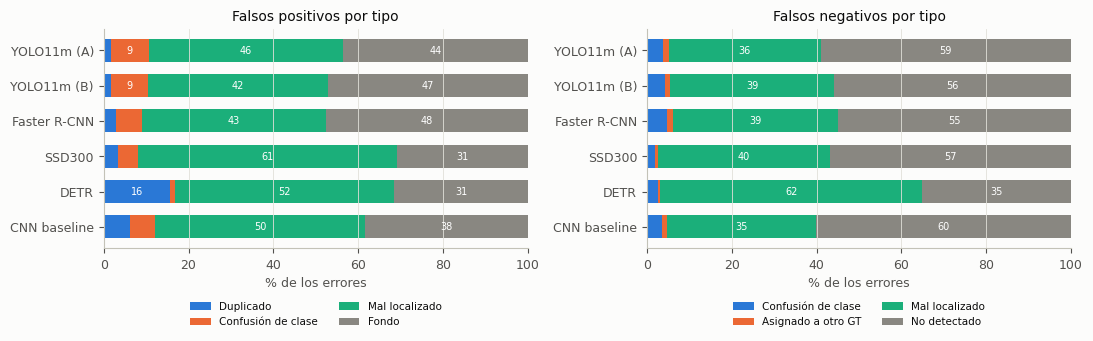

In [7]:
def composicion(res, que):
    if que == "fp":
        df = res["pred"]; df = df[~df["tp"].astype(bool)]; tipos = TIPOS_FP
    else:
        df = res["gt"]; df = df[~df["det"].astype(bool)]; tipos = TIPOS_FN
    cnt = np.bincount(df["tipo"].astype(int), minlength=4)[:4]
    return cnt, tipos


TAX_FP = pd.DataFrame({e: composicion(RES[e], "fp")[0] for e in MODELOS}, index=TIPOS_FP).T
TAX_FN = pd.DataFrame({e: composicion(RES[e], "fn")[0] for e in MODELOS}, index=TIPOS_FN).T
print("FP por tipo (conteo)"); display(TAX_FP)
print("FP por tipo (%)");      display((100 * TAX_FP.div(TAX_FP.sum(1), axis=0)).round(1))
print("FN por tipo (conteo)"); display(TAX_FN)
print("FN por tipo (%)");      display((100 * TAX_FN.div(TAX_FN.sum(1), axis=0)).round(1))
TAX_FP.to_csv(TAB_DIR / "02_taxonomia_fp.csv"); TAX_FN.to_csv(TAB_DIR / "03_taxonomia_fn.csv")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, tab, tipos, tit in ((axs[0], TAX_FP, TIPOS_FP, "Falsos positivos por tipo"),
                            (axs[1], TAX_FN, TIPOS_FN, "Falsos negativos por tipo")):
    pct = 100 * tab.div(tab.sum(1), axis=0)
    left = np.zeros(len(pct))
    for k, t in enumerate(tipos):
        ax.barh(pct.index, pct[t], left=left, color=COL_TIPOS[k], label=t, height=0.65)
        for y, (l, v) in enumerate(zip(left, pct[t])):
            if v >= 7:
                ax.text(l + v / 2, y, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white")
        left += pct[t].values
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.set_xlabel("% de los errores"); ax.set_title(tit)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=7.5)
    ax.grid(axis="y", visible=False)
guardar(fig, "01_taxonomia_errores")

### 3.3 FP y FN por clase

Tasa de FN por clase (1 − recall) y de FP por clase (1 − precisión), junto al número de
instancias: una tasa alta con pocas instancias es poco fiable.

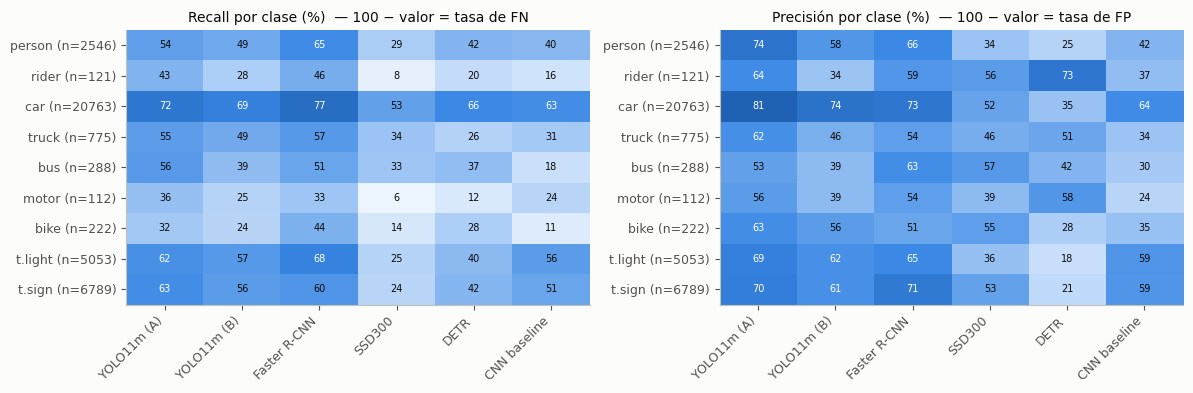

In [8]:
PC = {e: por_clase(RES[e]) for e in MODELOS}
REC_C = pd.DataFrame({e: PC[e]["R"].values for e in MODELOS}, index=NAMES_K)
PRE_C = pd.DataFrame({e: PC[e]["P"].values for e in MODELOS}, index=NAMES_K)
N_GT_C = PC[MODELOS[0]]["gt"].values
ylab = [f"{n} (n={g})" for n, g in zip(NAMES_S, N_GT_C)]

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
heatmap(axs[0], 100 * REC_C.values, MODELOS, ylab, fmt="{:.0f}", vmax=100)
axs[0].set_title("Recall por clase (%)  — 100 − valor = tasa de FN")
heatmap(axs[1], 100 * PRE_C.values, MODELOS, ylab, fmt="{:.0f}", vmax=100)
axs[1].set_title("Precisión por clase (%)  — 100 − valor = tasa de FP")
guardar(fig, "02_recall_precision_por_clase")
REC_C.mul(100).round(1).to_csv(TAB_DIR / "04_recall_por_clase.csv")
PRE_C.mul(100).round(1).to_csv(TAB_DIR / "05_precision_por_clase.csv")

### 3.4 FN por tamaño del objeto

El 55 % de las instancias mide menos de 32 px nativos. Si los FN se concentran en los
objetos pequeños, el recall bajo es en buena parte un problema de **resolución**, no de
clasificación. Se muestra el recall por tamaño COCO y la curva continua frente al lado
equivalente del objeto (raíz del área), con intervalo de Wilson al 95 %.

Instancias de GT por tamaño: {'small (<32²)': np.int64(20155), 'medium': np.int64(11858), 'large (>96²)': np.int64(4656)} | fracción small: 0.55
Recall (%) por tamaño


,small (<32²),medium,large (>96²)
modelo,,,
YOLO11m (A),53.7,79.2,93.1
YOLO11m (B),48.2,74.9,90.1
Faster R-CNN,58.6,81.4,93.1
SSD300,18.5,60.7,90.1
DETR,36.6,71.9,88.0
CNN baseline,46.3,68.0,71.3


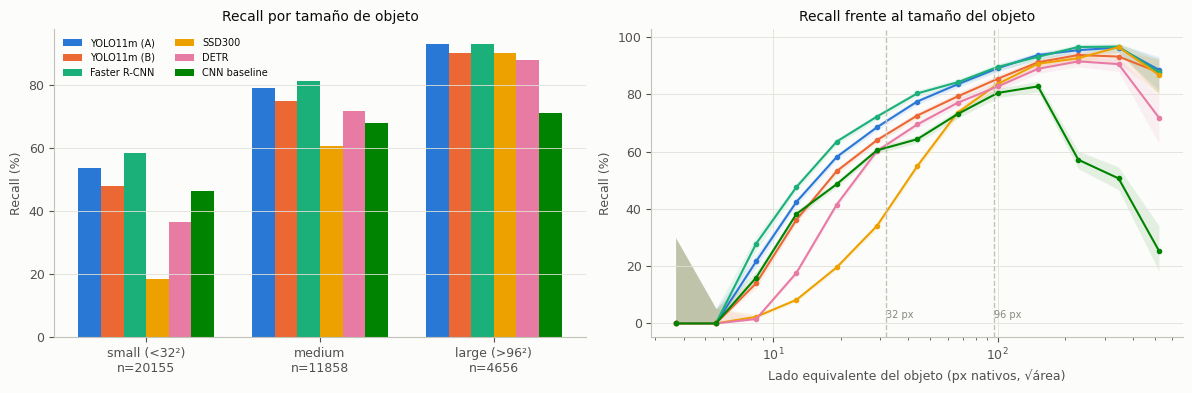

In [9]:
def cat_tam(area):
    return np.where(area < AREA_SMALL, 0, np.where(area < AREA_LARGE, 1, 2))


NOM_TAM = ["small (<32²)", "medium", "large (>96²)"]
filas = []
for e in MODELOS:
    g = RES[e]["gt"]; t = cat_tam(g["area"].values)
    d = g["det"].astype(bool).values
    filas.append({"modelo": e, **{NOM_TAM[k]: round(100 * d[t == k].mean(), 1) for k in range(3)}})
REC_TAM = pd.DataFrame(filas).set_index("modelo")
n_tam = np.bincount(cat_tam(RES[MODELOS[0]]["gt"]["area"].values), minlength=3)
print("Instancias de GT por tamaño:", dict(zip(NOM_TAM, n_tam)),
      "| fracción small:", round(n_tam[0] / n_tam.sum(), 3))
print("Recall (%) por tamaño"); display(REC_TAM)
REC_TAM.to_csv(TAB_DIR / "06_recall_por_tamano.csv")

# curva continua
lado = np.sqrt(RES[MODELOS[0]]["gt"]["area"].values)
bordes = np.geomspace(max(lado.min(), 3), lado.max(), 14)
cent = np.sqrt(bordes[:-1] * bordes[1:])
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
ax = axs[0]
ancho = 0.13
for k, e in enumerate(MODELOS):
    ax.bar(np.arange(3) + (k - 2.5) * ancho, REC_TAM.loc[e].values, ancho, color=COLORES[e], label=e)
ax.set_xticks(range(3)); ax.set_xticklabels([f"{n}\nn={c}" for n, c in zip(NOM_TAM, n_tam)])
ax.set_ylabel("Recall (%)"); ax.set_title("Recall por tamaño de objeto"); ax.legend(fontsize=7, ncol=2)
ax.grid(axis="x", visible=False)
ax = axs[1]
for e in MODELOS:
    g = RES[e]["gt"]; d = g["det"].astype(bool).values; l = np.sqrt(g["area"].values)
    ys, lo, hi = [], [], []
    for a, b in zip(bordes[:-1], bordes[1:]):
        m = (l >= a) & (l < b)
        k_, n_ = int(d[m].sum()), int(m.sum())
        ys.append(k_ / n_ if n_ else np.nan)
        lo_, hi_ = wilson(k_, n_); lo.append(lo_); hi.append(hi_)
    ax.plot(cent, 100 * np.array(ys), "-o", ms=3, color=COLORES[e], label=e)
    ax.fill_between(cent, 100 * np.array(lo), 100 * np.array(hi), color=COLORES[e], alpha=0.10, lw=0)
for v, t in ((32, "32 px"), (96, "96 px")):
    ax.axvline(v, color=BASELINE_COLOR, ls="--", lw=1); ax.text(v, 2, t, color=INK_MUTED, fontsize=7)
ax.set_xscale("log"); ax.set_xlabel("Lado equivalente del objeto (px nativos, √área)")
ax.set_ylabel("Recall (%)"); ax.set_title("Recall frente al tamaño del objeto")
guardar(fig, "03_recall_por_tamano")

**Tipo de FN según el tamaño**: para cada modelo, qué parte de los objetos perdidos son
pequeños y cuál es su causa dominante. Si casi todos los FN pequeños son *no detectado*,
el modelo directamente no los ve.

In [10]:
filas = []
for e in MODELOS:
    g = RES[e]["gt"]; fn = g[~g["det"].astype(bool)]
    t = cat_tam(fn["area"].values)
    fila = {"modelo": e, "% FN que son small": round(100 * (t == 0).mean(), 1)}
    for k in range(3):
        sub = fn[t == k]["tipo"].astype(int)
        fila[f"{NOM_TAM[k].split()[0]}: % no detectado"] = round(100 * (sub == 3).mean(), 1) if len(sub) else np.nan
    filas.append(fila)
FN_TAM = pd.DataFrame(filas).set_index("modelo")
display(FN_TAM)
FN_TAM.to_csv(TAB_DIR / "07_fn_por_tamano_y_tipo.csv")

,% FN que son small,small: % no detectado,medium: % no detectado,large: % no detectado
modelo,,,,
YOLO11m (A),77.0,61.4,53.2,37.3
YOLO11m (B),75.2,57.1,54.0,41.0
Faster R-CNN,76.8,58.3,46.3,28.4
SSD300,76.2,60.7,45.2,39.2
DETR,76.6,34.2,36.4,45.5
CNN baseline,67.9,63.1,50.1,63.8


### 3.5 FN por condición de la escena (hora del día y clima)

Relevante para el caso práctico: un sistema de conducción no solo ve de día. Los
atributos proceden del JSON de BDD100K. **Cuidado con los grupos pequeños** (se muestra
`n` de cada uno): un recall calculado sobre pocos objetos no es fiable.

Recall (%) por hora del dia


,n GT,YOLO11m (A),YOLO11m (B),Faster R-CNN,SSD300,DETR,CNN baseline
daytime,20163,67.7,62.4,71.4,40.7,55.2,56.6
night,13803,65.7,61.9,68.7,42.1,53.9,56.6
dawn/dusk,2637,67.8,62.1,71.0,40.1,53.1,55.9


Recall (%) por clima


,n GT,YOLO11m (A),YOLO11m (B),Faster R-CNN,SSD300,DETR,CNN baseline
clear,19320,66.4,62.2,69.6,41.5,54.8,56.8
overcast,4900,67.9,63.7,72.2,41.6,55.6,58.3
snowy,2810,67.2,61.5,70.1,41.1,53.6,54.7
partly cloudy,2489,67.9,61.8,70.6,39.4,53.3,55.0
rainy,2305,65.6,60.2,69.1,41.0,53.3,53.7


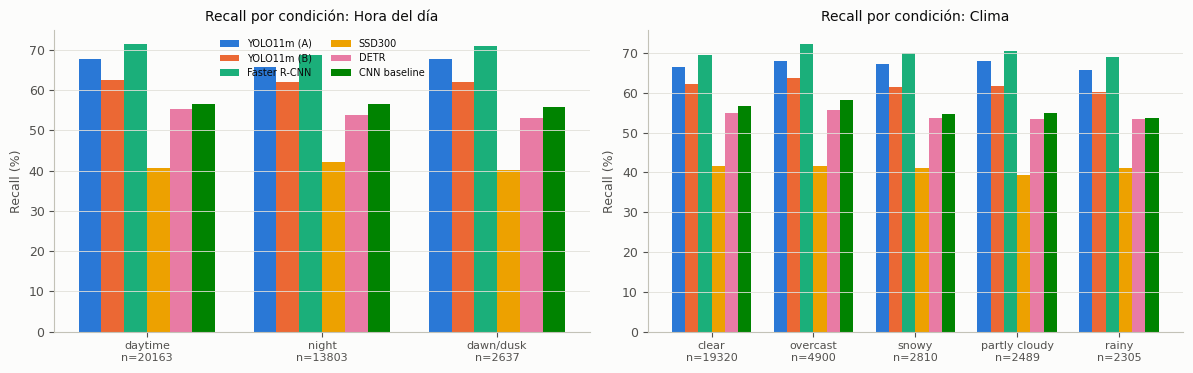

In [11]:
def recall_por(col, minimo=500):
    g0 = RES[MODELOS[0]]["gt"]
    cnt = g0[col].value_counts()
    cats = [c for c in cnt.index if cnt[c] >= minimo and c not in ("?", "undefined")]
    tab = pd.DataFrame({e: {c: 100 * RES[e]["gt"].loc[RES[e]["gt"][col] == c, "det"].astype(bool).mean()
                            for c in cats} for e in MODELOS})
    tab.insert(0, "n GT", [int(cnt[c]) for c in tab.index])
    return tab.round(1)


REC_HORA = recall_por("timeofday"); REC_CLIMA = recall_por("weather")
print("Recall (%) por hora del dia"); display(REC_HORA)
print("Recall (%) por clima");        display(REC_CLIMA)
REC_HORA.to_csv(TAB_DIR / "08_recall_por_hora.csv"); REC_CLIMA.to_csv(TAB_DIR / "09_recall_por_clima.csv")

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, tab, tit in ((axs[0], REC_HORA, "Hora del día"), (axs[1], REC_CLIMA, "Clima")):
    cats = list(tab.index); w = 0.13
    for k, e in enumerate(MODELOS):
        ax.bar(np.arange(len(cats)) + (k - 2.5) * w, tab[e].values, w, color=COLORES[e], label=e)
    ax.set_xticks(range(len(cats)))
    ax.set_xticklabels([f"{c}\nn={n}" for c, n in zip(cats, tab["n GT"])], fontsize=8)
    ax.set_ylabel("Recall (%)"); ax.set_title(f"Recall por condición: {tit}")
    ax.grid(axis="x", visible=False)
axs[0].legend(fontsize=7, ncol=2)
guardar(fig, "04_recall_por_condicion")

## 4. Matrices de confusión

Filas = clase real (GT), columnas = clase predicha; la última fila/columna es **fondo**.
El emparejamiento es por IoU ≥ 0,5 **sin exigir la misma clase** (como la matriz de
Ultralytics), para que una confusión de clase aparezca como tal y no como un FP más un
FN.

- Celda **(clase, fondo)** = objeto no detectado (FN).
- Celda **(fondo, clase)** = detección sin objeto (FP).
- Fuera de la diagonal, entre clases = **confusión de clase**.

Se normaliza **por filas** (cada fila suma 100 %): la diagonal es el recall de la clase
y el resto reparte el error. En la fila *fondo* el porcentaje es la fracción de los FP
que se predicen como cada clase.

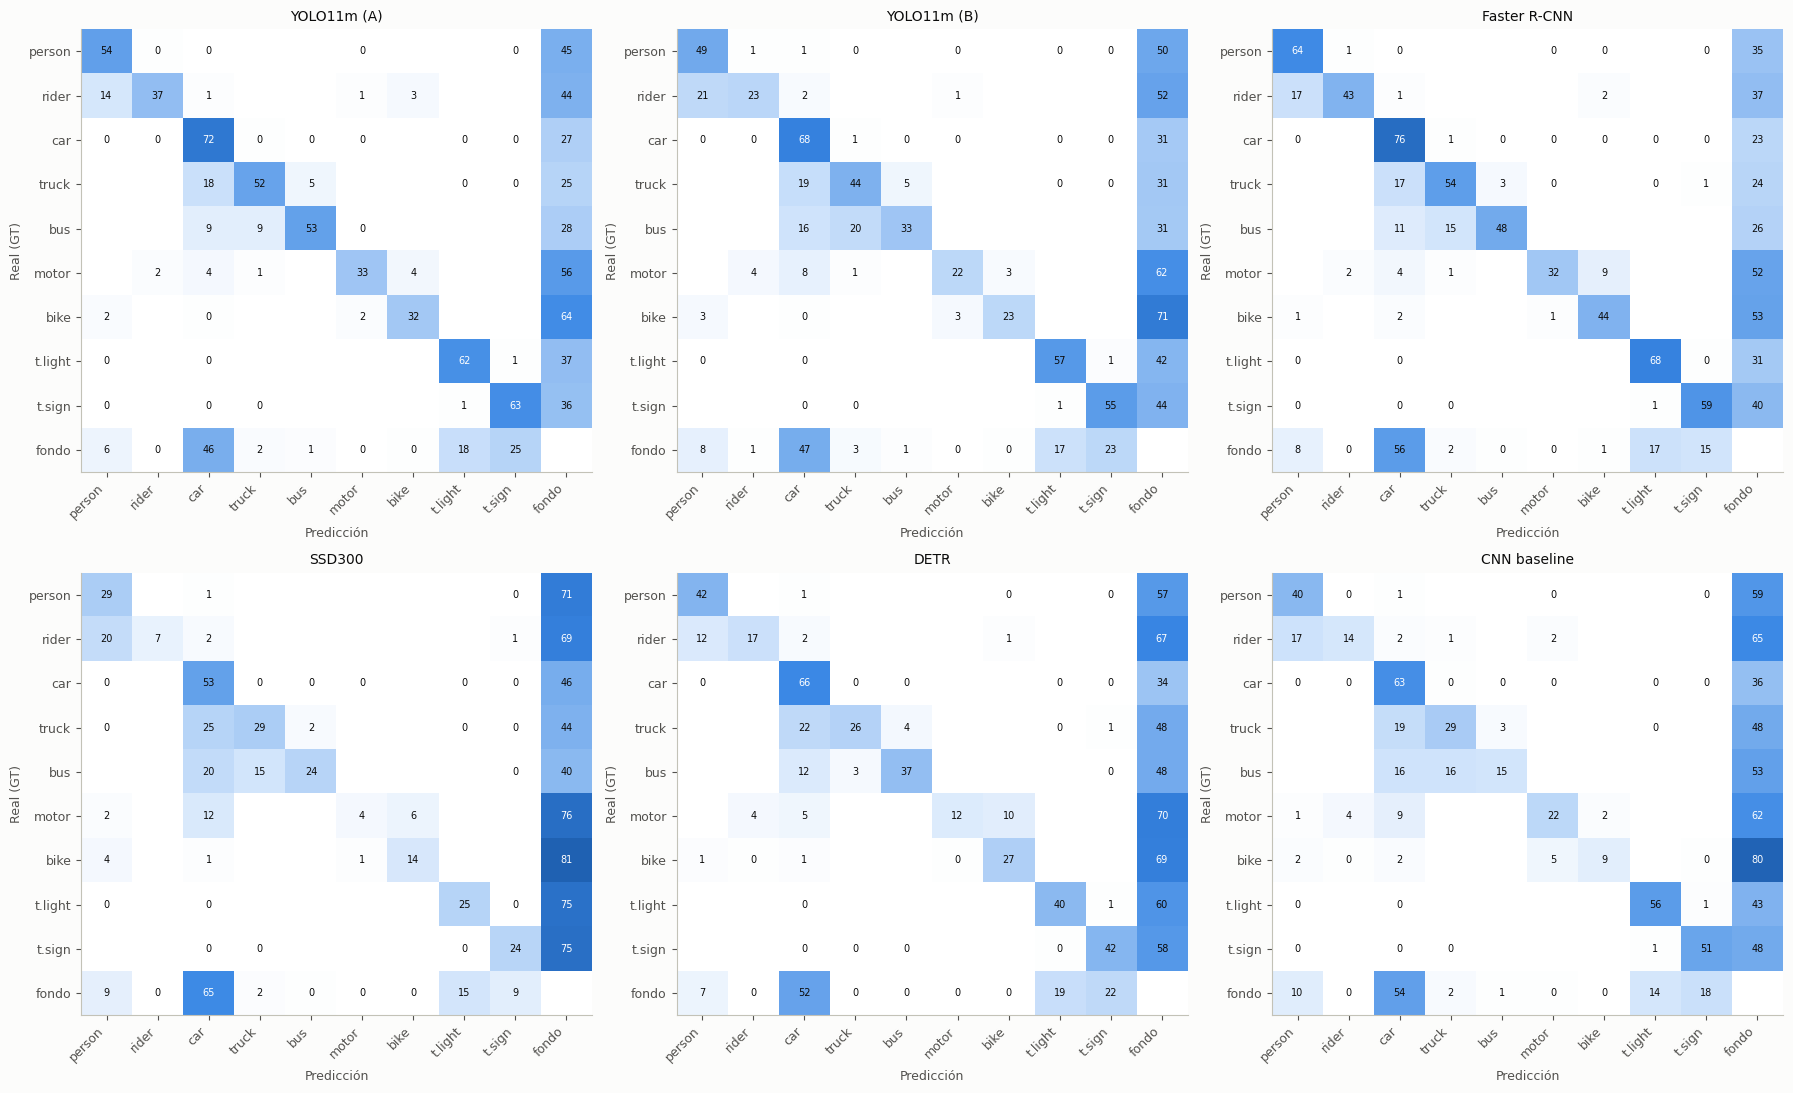

In [12]:
etiq = NAMES_S + ["fondo"]
fig, axs = plt.subplots(2, 3, figsize=(18, 11))
for ax, e in zip(axs.ravel(), MODELOS):
    cm = RES[e]["cm"].astype(float)
    norm = 100 * cm / np.clip(cm.sum(1, keepdims=True), 1, None)
    heatmap(ax, norm, etiq, etiq, fmt="{:.0f}", vmax=100, fs=7)
    ax.set_title(e); ax.set_xlabel("Predicción"); ax.set_ylabel("Real (GT)")
guardar(fig, "05_matrices_confusion")

# version en conteos, util para tablas
for e in MODELOS:
    pd.DataFrame(RES[e]["cm"], index=etiq, columns=etiq).to_csv(
        TAB_DIR / f"10_confusion_{e.replace(' ', '_').replace('(', '').replace(')', '')}.csv")

### 4.1 Confusiones entre clases más frecuentes

Solo confusiones **entre clases** (se excluye el fondo). El porcentaje es la fracción de
los objetos de la clase real que se detectan, pero con otra clase. Son los pares que un
tribunal pregunta: ¿se confunde `car` con `truck`? ¿`person` con `rider`? ¿`bike` con `motor`?

In [ ]:
filas = []
for e in MODELOS:
    cm = RES[e]["cm"]
    for i in range(NK):
        for j in range(NK):
            if i != j and cm[i, j] > 0:
                filas.append({"modelo": e, "real": NAMES_K[i], "predicho": NAMES_K[j],
                              "n": int(cm[i, j]), "% de la clase real": round(100 * cm[i, j] / max(cm[i].sum(), 1), 2)})
CONF = pd.DataFrame(filas)
TOP = CONF.sort_values(["modelo", "n"], ascending=[True, False]).groupby("modelo").head(5)
display(TOP.reset_index(drop=True))
CONF.to_csv(TAB_DIR / "11_confusiones_entre_clases.csv", index=False)

# pares tipicos de la conduccion, en las dos direcciones
PARES = [("car", "truck"), ("car", "bus"), ("truck", "bus"), ("person", "rider"),
         ("bike", "motor"), ("traffic light", "traffic sign"), ("rider", "bike")]
filas = []
for e in MODELOS:
    cm = RES[e]["cm"]; fila = {"modelo": e}
    for a, b in PARES:
        ia, ib = NAMES_K.index(a), NAMES_K.index(b)
        fila[f"{a}↔{b}"] = int(cm[ia, ib] + cm[ib, ia])
    filas.append(fila)
PARES_DF = pd.DataFrame(filas).set_index("modelo")
print("Confusiones en ambos sentidos (nº de objetos) entre pares de clases habituales")
display(PARES_DF)
PARES_DF.to_csv(TAB_DIR / "12_confusiones_pares.csv")

# peso de la confusion de clase frente al resto de causas de fallo
filas = []
for e in MODELOS:
    cm = RES[e]["cm"]; ng = cm[:NK].sum()
    conf_cls = cm[:NK, :NK].sum() - np.trace(cm[:NK, :NK])
    perdidos = cm[:NK, NK].sum()
    filas.append({"modelo": e, "GT": int(ng), "bien clasificados": int(np.trace(cm[:NK, :NK])),
                  "confundidos": int(conf_cls), "no detectados": int(perdidos),
                  "% confundidos del total de fallos": round(100 * conf_cls / max(conf_cls + perdidos, 1), 1)})
display(pd.DataFrame(filas).set_index("modelo"))

## 5. Correlaciones

> Todas son **exploratorias**: n = 9 clases por modelo, n = 6 modelos (o 18 runs).
> Un p-valor bajo con n tan pequeño no es una prueba, y una correlación no implica
> causa. Se reportan porque responden a una pregunta directa del tribunal, no para
> sustituir el análisis estadístico de la memoria.

### 5.1 Instancias de entrenamiento… por clase: frecuencia, tamaño y AP

Pregunta: *¿las clases con más instancias tienen mejor AP?* La respuesta ingenua es sí,
pero la frecuencia está **confundida con el tamaño del objeto** (`car` es frecuente y
grande; `traffic light` es frecuente pero pequeño) y con la cobertura de COCO. Por eso
se calcula también la correlación **parcial**: la de cada variable con el AP descontando
el efecto de la otra.

Se usa la frecuencia en **validación** (n GT) como aproximación de la de entrenamiento:
las proporciones de clase son idénticas en train/val/test hasta la 2ª decimal (memoria,
sec. Características del conjunto).

In [ ]:
def parcial_spearman(x, y, z):
    # correlacion de Spearman entre x e y controlando z (residuos de los rangos)
    rx, ry, rz = (stats.rankdata(v) for v in (x, y, z))
    ex = rx - np.polyval(np.polyfit(rz, rx, 1), rz)
    ey = ry - np.polyval(np.polyfit(rz, ry, 1), rz)
    r = np.corrcoef(ex, ey)[0, 1]
    n = len(x)
    t = r * np.sqrt((n - 3) / max(1 - r ** 2, 1e-12))
    return r, 2 * stats.t.sf(abs(t), n - 3)


gt0 = RES[MODELOS[0]]["gt"]
lado_med = np.array([np.median(np.sqrt(gt0.loc[gt0["cls"] == k, "area"])) for k in range(NK)])
n_gt = N_GT_C.astype(float)
log_n = np.log10(n_gt)
print("Lado mediano (px nativos) por clase:", dict(zip(NAMES_S, lado_med.round(1))))
print("Correlacion entre log(n instancias) y tamaño mediano ENTRE clases:",
      "rho=%.2f p=%.3f" % stats.spearmanr(log_n, lado_med))

AP_C = pd.DataFrame({e: [EVAL[e]["per_class"][n]["ap50_95"] for n in NAMES_K] for e in MODELOS}, index=NAMES_K)
AP_C = AP_C.where(AP_C > -99)

filas = []
for e in MODELOS:
    ap = AP_C[e].values
    r1, p1 = stats.spearmanr(log_n, ap)
    r2, p2 = stats.spearmanr(lado_med, ap)
    r3, p3 = parcial_spearman(log_n, ap, lado_med)
    r4, p4 = parcial_spearman(lado_med, ap, log_n)
    r5, p5 = stats.spearmanr(log_n, REC_C[e].values)
    filas.append({"modelo": e, "ρ(n, AP)": r1, "p": p1, "ρ(tamaño, AP)": r2, "p ": p2,
                  "ρ(n, AP | tamaño)": r3, "p  ": p3, "ρ(tamaño, AP | n)": r4, "p   ": p4,
                  "ρ(n, recall)": r5, "p    ": p5})
CORR_CLASE = pd.DataFrame(filas).set_index("modelo").round(2)
display(CORR_CLASE)
CORR_CLASE.to_csv(TAB_DIR / "13_correlacion_por_clase.csv")
print("Lectura: si ρ(n, AP | tamaño) cae mucho respecto a ρ(n, AP), la frecuencia 'explicaba' el AP\n"
      "solo porque las clases frecuentes son mas grandes. Con n=9, |ρ| < 0.67 no es significativo (p<0.05).")

fig, axs = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True)
for ax, e in zip(axs.ravel(), MODELOS):
    ap = AP_C[e].values
    for k, n in enumerate(NAMES_K):
        marcador = "o" if EN_COCO[n] else "s"
        ax.scatter(log_n[k], ap[k], s=40 + 8 * lado_med[k] / 3, color=COLORES[e], marker=marcador,
                   alpha=0.85, edgecolor="white", lw=0.6)
        ax.annotate(NAMES_S[k], (log_n[k], ap[k]), fontsize=6.5, xytext=(4, 3), textcoords="offset points",
                    color=INK_SECONDARY)
    r, p = stats.spearmanr(log_n, ap)
    ax.set_title(f"{e}   ρ={r:.2f} (p={p:.2f})")
    ax.set_ylabel("AP@50–95 (%)")
for ax in axs[1]:
    ax.set_xlabel("log10(instancias de la clase)")
fig.text(0.5, -0.01, "Círculo = clase presente en MS COCO; cuadrado = rider / traffic sign (sin equivalente directo). "
         "Tamaño del punto ∝ tamaño mediano del objeto.", ha="center", fontsize=8, color=INK_MUTED)
guardar(fig, "06_correlacion_instancias_ap")

### 5.2 Tamaño del objeto ↔ detección (a nivel de objeto)

Con ~36 000 objetos, aquí sí hay potencia estadística. Se mide la relación entre el
tamaño del objeto y que sea detectado: correlación de Spearman con el indicador
detectado/perdido, y el **AUC** del tamaño como predictor de la detección (0,5 = el
tamaño no informa; 1,0 = el tamaño lo explica todo).

In [ ]:
filas = []
for e in MODELOS:
    g = RES[e]["gt"]; d = g["det"].astype(int).values; l = np.log10(np.sqrt(g["area"].values))
    rho, p = stats.spearmanr(l, d)
    filas.append({"modelo": e, "ρ(log tamaño, detectado)": rho, "p": p,
                  "AUC(tamaño→detectado)": roc_auc_score(d, l)})
CORR_TAM = pd.DataFrame(filas).set_index("modelo").round(3)
display(CORR_TAM)
CORR_TAM.to_csv(TAB_DIR / "14_correlacion_tamano_deteccion.csv")

### 5.3 Confianza ↔ acierto (calibración)

¿Se puede fiar uno del `score`? Se evalúa sobre **todas** las detecciones a `conf ≥ 0,001`:
el **AUC** de `score → es TP` (qué tan bien separa el score los aciertos de los FP) y el
diagrama de fiabilidad (fracción real de TP por tramo de score). La diagonal sería un
modelo perfectamente calibrado. Es la base para elegir un umbral de operación en un caso
real. También se correlaciona el score con el **IoU** de los TP (¿las cajas más seguras
están mejor ajustadas?).

In [ ]:
FULL = {e: analizar(PREDS[e], CONF_CACHE) for e in tqdm(MODELOS, desc="analisis a conf=0.001")}
# El TP greedy por score no depende de las detecciones de menor score: los TP a un umbral
# mayor son un subconjunto de los de conf=0.001. Se comprueba contra el analisis a umbral de max-F1.
for e in MODELOS:
    f = FULL[e]["pred"]
    tp_full = int(f.loc[f["score"] >= THR_OP[e], "tp"].sum())
    tp_op = int(RES[e]["pred"]["tp"].sum())
    assert tp_full == tp_op, (e, tp_full, tp_op)
print("OK: los TP a conf=0.001 filtrados por umbral coinciden con el analisis directo en el umbral.")

filas = []
fig, ax = plt.subplots(figsize=(5.6, 5))
ax.plot([0, 1], [0, 1], color=BASELINE_COLOR, ls="--", lw=1, label="calibración perfecta")
for e in MODELOS:
    p = FULL[e]["pred"]; s = p["score"].values; tp = p["tp"].astype(int).values
    bins = np.linspace(0, 1, 11); idx = np.clip(np.digitize(s, bins) - 1, 0, 9)
    xs = [s[idx == b].mean() for b in range(10) if (idx == b).sum() >= 30]
    ys = [tp[idx == b].mean() for b in range(10) if (idx == b).sum() >= 30]
    ax.plot(xs, ys, "-o", ms=3, color=COLORES[e], label=e)
    tpm = p["tp"].astype(bool).values
    rho_iou, _ = stats.spearmanr(s[tpm], p["iou"].values[tpm])
    filas.append({"modelo": e, "AUC(score→TP)": roc_auc_score(tp, s), "ρ(score, IoU) en TP": rho_iou,
                  "score medio TP": s[tpm].mean(), "score medio FP": s[~tpm].mean()})
ax.set_xlabel("Score medio del tramo"); ax.set_ylabel("Fracción de TP")
ax.set_title("Diagrama de fiabilidad (IoU ≥ 0,5)"); ax.legend(fontsize=7)
guardar(fig, "07_calibracion")
CALIB = pd.DataFrame(filas).set_index("modelo").round(3)
display(CALIB); CALIB.to_csv(TAB_DIR / "15_calibracion.csv")

### 5.4 Densidad de la escena ↔ recall

¿Las escenas con más objetos pierden más? Correlación de Spearman, por imagen, entre el
número de objetos del GT y el recall de esa imagen (solo imágenes con GT). Puede deberse
a oclusión y a solapamiento, pero también a que las escenas densas tienen más objetos
pequeños: no se puede separar con estos datos.

In [ ]:
filas = []
fig, ax = plt.subplots(figsize=(6.2, 4.2))
for e in MODELOS:
    im = RES[e]["img"]; im = im[im["n_gt"] > 0].copy()
    im["rec"] = im["n_tp"] / im["n_gt"]
    rho, p = stats.spearmanr(im["n_gt"], im["rec"])
    filas.append({"modelo": e, "ρ(nº objetos, recall de la imagen)": rho, "p": p,
                  "recall medio img": im["rec"].mean()})
    q = pd.qcut(im["n_gt"], 6, duplicates="drop")
    g = im.groupby(q, observed=True).agg(x=("n_gt", "mean"), y=("rec", "mean"))
    ax.plot(g["x"], 100 * g["y"], "-o", ms=3, color=COLORES[e], label=e)
ax.set_xlabel("Objetos en la imagen (media del tramo)"); ax.set_ylabel("Recall medio (%)")
ax.set_title("Recall frente a la densidad de la escena"); ax.legend(fontsize=7)
guardar(fig, "08_recall_vs_densidad")
CORR_DENS = pd.DataFrame(filas).set_index("modelo").round(3)
display(CORR_DENS); CORR_DENS.to_csv(TAB_DIR / "16_correlacion_densidad.csv")

### 5.5 ¿Fallan los modelos en los mismos objetos?

Se construye, para cada modelo, el indicador «objeto perdido» sobre **el mismo GT**, y se
calcula el coeficiente φ (correlación de Pearson entre indicadores binarios) entre pares
de modelos. Un φ alto significa que los errores son **sistemáticos** (objetos
intrínsecamente difíciles); un φ bajo, que los modelos se equivocan en sitios distintos
y un ensamble podría ayudar. Cada modelo está en su propio umbral de máximo F1.

In [ ]:
MISS = np.stack([~RES[e]["gt"]["det"].astype(bool).values for e in MODELOS])      # (6, N)
phi = np.corrcoef(MISS.astype(float))
fig, ax = plt.subplots(figsize=(5.4, 4.6))
M = pd.DataFrame(phi, index=MODELOS, columns=MODELOS)
heatmap(ax, M.values, MODELOS, MODELOS, fmt="{:.2f}", vmax=1.0, fs=8)
ax.set_title("Correlación (φ) entre los objetos perdidos de cada modelo")
guardar(fig, "09_correlacion_errores_modelos")
M.round(3).to_csv(TAB_DIR / "17_phi_errores_entre_modelos.csv")

todos = MISS.all(0); alguno = MISS.any(0); ninguno = ~alguno
lado_g = np.sqrt(RES[MODELOS[0]]["gt"]["area"].values)
cls_g = RES[MODELOS[0]]["gt"]["cls"].astype(int).values
print(f"Objetos perdidos por TODOS los modelos : {todos.sum():>6} ({100*todos.mean():.1f}% del GT)")
print(f"Perdidos por AL MENOS uno              : {alguno.sum():>6} ({100*alguno.mean():.1f}%)")
print(f"Detectados por todos                   : {ninguno.sum():>6} ({100*ninguno.mean():.1f}%)")
print(f"Lado mediano — perdidos por todos: {np.median(lado_g[todos]):.1f} px | detectados por todos: {np.median(lado_g[ninguno]):.1f} px")
print("Clase de los objetos perdidos por todos:")
print(pd.Series(np.array(NAMES_K)[cls_g[todos]]).value_counts().to_string())

### 5.6 Precisión ↔ velocidad ↔ coste (a nivel de modelo)

Con los **18 runs** (6 configuraciones × 3 semillas) y con las 6 medias. Los 18 puntos no
son independientes (las semillas de una misma configuración se agrupan), así que los
p-valores con n = 18 **sobrestiman** la evidencia; la lectura honesta es la de n = 6 y,
sobre todo, la forma del gráfico: ¿la configuración más rápida es también la más precisa?

In [ ]:
filas = []
for etq, prefijo, *_ in CONFIGS:
    for s in (0, 1, 2):
        try:
            d = buscar_run(prefijo, s)
        except FileNotFoundError:
            continue
        j = json.loads((pesos_de(d).parent / "eval_results.json").read_text(encoding="utf-8"))
        filas.append({"modelo": etq, "semilla": s, "mAP@50-95": j["map50_95"], "FPS": j["fps"],
                      "GFLOPs": j.get("gflops"), "AP small": j["map_small"],
                      "precision": j["precision"], "recall": j["recall"]})
RUNS18 = pd.DataFrame(filas)
print(len(RUNS18), "runs")
MEDIAS = RUNS18.groupby("modelo").mean(numeric_only=True).loc[MODELOS]

PARES_M = [("mAP@50-95", "FPS"), ("mAP@50-95", "GFLOPs"), ("mAP@50-95", "AP small"),
           ("recall", "AP small"), ("precision", "recall")]
filas = []
for a, b in PARES_M:
    r18, p18 = stats.spearmanr(RUNS18[a], RUNS18[b])
    r6, p6 = stats.spearmanr(MEDIAS[a], MEDIAS[b])
    rp, pp = stats.pearsonr(MEDIAS[a], MEDIAS[b])
    filas.append({"par": f"{a}  vs  {b}", "Spearman n=6": r6, "p (n=6)": p6, "Pearson n=6": rp,
                  "Spearman n=18": r18, "p (n=18, sobrestimado)": p18})
CORR_MOD = pd.DataFrame(filas).set_index("par").round(3)
display(CORR_MOD); CORR_MOD.to_csv(TAB_DIR / "18_correlacion_entre_modelos.csv")

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
for ax, (a, b), log in zip(axs, [("FPS", "mAP@50-95"), ("GFLOPs", "mAP@50-95"), ("AP small", "mAP@50-95")],
                           [True, True, False]):
    for e in MODELOS:
        s = RUNS18[RUNS18["modelo"] == e]
        ax.scatter(s[a], s[b], color=COLORES[e], s=28, alpha=0.8, edgecolor="white", lw=0.5)
        ax.annotate(e, (s[a].mean(), s[b].mean()), fontsize=7, xytext=(5, 4), textcoords="offset points",
                    color=INK_SECONDARY)
    if log:
        ax.set_xscale("log")
    ax.set_xlabel(a + (" (escala log)" if log else "")); ax.set_ylabel(b)
axs[0].axvline(30, color=BASELINE_COLOR, ls="--", lw=1); axs[0].text(31, 4, "30 FPS", fontsize=7, color=INK_MUTED)
axs[0].set_title("Precisión frente a velocidad"); axs[1].set_title("Precisión frente a coste")
axs[2].set_title("Precisión frente a AP en objetos pequeños")
guardar(fig, "10_correlacion_modelos")

## 6. Punto de operación: cuántos FP y FN según el umbral

Todo lo anterior está en el umbral de máximo F1, que **equilibra** precisión y recall.
En una aplicación real el coste de un FN (peatón no detectado) no es el de un FP
(frenazo innecesario), y el umbral se elige en consecuencia. Aquí se ve el compromiso
completo, **a igualdad de condiciones entre modelos**.

Los TP a cada umbral salen de la ejecución a `conf = 0,001` (el emparejamiento greedy por
score no depende de las detecciones de menor score; se comprobó en la celda 5.3).

In [ ]:
GRID = np.concatenate([[CONF_CACHE], np.linspace(0.02, 0.95, 94)])
NGT_C = N_GT_C.astype(float)


def curva(etq):
    p = FULL[etq]["pred"]; s = p["score"].values; c = p["cls"].astype(int).values; tp = p["tp"].astype(float).values
    n_gt_tot = NGT_C.sum()
    filas = []
    for t in GRID:
        sel = s >= t
        pred_c = np.bincount(c[sel], minlength=NK).astype(float)
        tp_c = np.bincount(c[sel], weights=tp[sel], minlength=NK)
        P_c = np.where(pred_c > 0, tp_c / np.clip(pred_c, 1, None), 1.0)
        R_c = tp_c / NGT_C
        F_c = 2 * P_c * R_c / (P_c + R_c + 1e-16)
        n_tp, n_pred = tp[sel].sum(), sel.sum()
        filas.append({"thr": t, "P": P_c.mean(), "R": R_c.mean(), "F1": F_c.mean(),
                      "FP/img": (n_pred - n_tp) / len(STEMS), "FN/img": (n_gt_tot - n_tp) / len(STEMS)})
    return pd.DataFrame(filas)


CURVAS = {e: curva(e) for e in MODELOS}

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for e in MODELOS:
    cv = CURVAS[e]
    axs[0].plot(cv["thr"], 100 * cv["R"], color=COLORES[e], label=e)
    axs[1].plot(cv["thr"], 100 * cv["P"], color=COLORES[e])
    axs[2].plot(cv["FP/img"], cv["FN/img"], color=COLORES[e])
    i = (cv["thr"] - THR_OP[e]).abs().idxmin()
    axs[0].scatter(cv["thr"][i], 100 * cv["R"][i], color=COLORES[e], s=30, zorder=5, edgecolor="white")
    axs[1].scatter(cv["thr"][i], 100 * cv["P"][i], color=COLORES[e], s=30, zorder=5, edgecolor="white")
    axs[2].scatter(cv["FP/img"][i], cv["FN/img"][i], color=COLORES[e], s=30, zorder=5, edgecolor="white")
axs[0].set_title("Recall macro frente al umbral"); axs[0].set_xlabel("Umbral de confianza"); axs[0].set_ylabel("%")
axs[1].set_title("Precisión macro frente al umbral"); axs[1].set_xlabel("Umbral de confianza")
axs[2].set_title("Compromiso FN / FP por imagen"); axs[2].set_xlabel("FP por imagen"); axs[2].set_ylabel("FN por imagen")
axs[2].set_xscale("log")
axs[0].legend(fontsize=7)
fig.text(0.5, -0.02, "Punto = umbral de máximo F1 de cada modelo.", ha="center", fontsize=8, color=INK_MUTED)
guardar(fig, "11_curvas_operacion")

# tabla a umbrales fijos
filas = []
for e in MODELOS:
    cv = CURVAS[e]
    for t in (0.05, 0.25, 0.50, 0.75):
        r = cv.iloc[(cv["thr"] - t).abs().idxmin()]
        filas.append({"modelo": e, "umbral": t, "R macro %": round(100 * r["R"], 1),
                      "P macro %": round(100 * r["P"], 1), "FP/img": round(r["FP/img"], 2),
                      "FN/img": round(r["FN/img"], 2)})
OPER = pd.DataFrame(filas)
display(OPER.pivot(index="modelo", columns="umbral", values=["R macro %", "FP/img", "FN/img"]).loc[MODELOS])
OPER.to_csv(TAB_DIR / "19_punto_de_operacion.csv", index=False)

In [ ]:
# Umbral que alcanza un recall objetivo y el coste en falsas alarmas (caso "seguridad")
OBJETIVO_RECALL = 0.60   # <- cambiar segun el caso de uso
filas = []
for e in MODELOS:
    cv = CURVAS[e]
    ok = cv[cv["R"] >= OBJETIVO_RECALL]
    if ok.empty:
        filas.append({"modelo": e, "recall máx. alcanzable %": round(100 * cv["R"].max(), 1),
                      f"umbral p/ R≥{OBJETIVO_RECALL:.0%}": "inalcanzable", "P macro %": np.nan, "FP/img": np.nan})
    else:
        r = ok.sort_values("thr").iloc[-1]    # el umbral mas alto que aun alcanza el objetivo
        filas.append({"modelo": e, "recall máx. alcanzable %": round(100 * cv["R"].max(), 1),
                      f"umbral p/ R≥{OBJETIVO_RECALL:.0%}": round(r["thr"], 3),
                      "P macro %": round(100 * r["P"], 1), "FP/img": round(r["FP/img"], 2)})
display(pd.DataFrame(filas).set_index("modelo"))

## 7. Resumen de cifras clave y exportación

Compila en `resumen_errores.json` las cifras que más probablemente se citen en la
defensa. Las tablas CSV de cada sección están en `tablas_errores/` y las figuras
(PNG + PDF) en `figuras_errores/`.

In [ ]:
resumen = {"semilla": SEMILLA, "iou_match": IOU_MATCH, "clases_excluidas": sorted(EXCLUIR), "modelos": {}}
for e in MODELOS:
    g = RES[e]["gt"]; d = g["det"].astype(bool).values; t = cat_tam(g["area"].values)
    fp_pct = 100 * TAX_FP.loc[e] / TAX_FP.loc[e].sum()
    fn_pct = 100 * TAX_FN.loc[e] / TAX_FN.loc[e].sum()
    resumen["modelos"][e] = {
        "umbral": round(THR_OP[e], 4),
        "FP_por_img": float(TABLA_GLOBAL.set_index("modelo").loc[e, "FP/img"]),
        "FN_por_img": float(TABLA_GLOBAL.set_index("modelo").loc[e, "FN/img"]),
        "FP_pct_micro": float(TABLA_GLOBAL.set_index("modelo").loc[e, "FP %"]),
        "FN_pct_micro": float(TABLA_GLOBAL.set_index("modelo").loc[e, "FN %"]),
        "taxonomia_FP_pct": {k: round(float(v), 1) for k, v in fp_pct.items()},
        "taxonomia_FN_pct": {k: round(float(v), 1) for k, v in fn_pct.items()},
        "recall_por_tamano_pct": {NOM_TAM[k]: round(100 * float(d[t == k].mean()), 1) for k in range(3)},
        "rho_n_AP_por_clase": float(CORR_CLASE.loc[e, "ρ(n, AP)"]),
        "rho_n_AP_controlando_tamano": float(CORR_CLASE.loc[e, "ρ(n, AP | tamaño)"]),
        "AUC_tamano_deteccion": float(CORR_TAM.loc[e, "AUC(tamaño→detectado)"]),
        "AUC_score_TP": float(CALIB.loc[e, "AUC(score→TP)"]),
    }
resumen["fn_comunes"] = {"perdidos_por_todos_pct": round(100 * float(todos.mean()), 1),
                         "perdidos_por_alguno_pct": round(100 * float(alguno.mean()), 1)}
(TAB_DIR / "resumen_errores.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(resumen, indent=2, ensure_ascii=False)[:3500])
print("\nFiguras:", len(list(FIG_DIR.glob('*.pdf'))), "PDF en", FIG_DIR, "| tablas:", len(list(TAB_DIR.glob('*.csv'))), "CSV en", TAB_DIR)

## Cómo usar estos resultados en la defensa

- **FP/FN**: citar la tabla 3.1 (por imagen y en %) y la taxonomía 3.2 para decir *qué
  tipo* de error domina, no solo cuántos hay.
- **Matriz de confusión**: si la confusión entre clases pesa poco frente a los objetos
  no detectados, el cuello de botella es la **detección** (resolución, tamaño), no la
  **clasificación**: es lo que justifica mirar el AP por tamaño.
- **Correlaciones**: presentarlas como exploratorias; la parcial (5.1) es la que evita
  la lectura ingenua de que «más instancias = mejor AP».
- **Caso práctico**: la sección 6 permite elegir el umbral según el coste de FN frente a
  FP, y 3.5 muestra si el rendimiento se sostiene de noche o con mal tiempo.
- **Límites a declarar**: una semilla, una partición (val), IoU 0,5, taxonomía simplificada.